# Lekce 4b (nepovinná): Komplexní obraz

V lekci 4 dostala každá frekvence komplexní číslo $F(u, v)$, šipku v rovině. Její délka byla amplituda vlny, úhel fáze. Tady dostane komplexní číslo každý **pixel**. Na barvě je pak vidět okem, co komplexní aritmetika dělá: násobení otáčí, sčítání posouvá a komplexně sdružené číslo zrcadlí.

Notebook je nepovinný a navazuje na sekce 1 a 2 lekce 4. Má dva krátké úkoly, kernel v Sáře a funkci v NumPy. Spusťte první tři buňky: první otevře v Sáře dokument s fotkou, druhá připraví převody do OKLabu, třetí interaktivní obrázky. Kód obrázků je schovaný, stačí hýbat nabídkami a posuvníky.

In [1]:
import sys
sys.path.insert(0, "lib")            # sara.py and its helpers live in lib/
import numpy as np
import sara

doc, layer, pixels = sara.init(width=512, height=512)   # a canvas the size of the photo
photo = doc.import_image("imgs/4/astronaut.png")        # a layer called "astronaut"

Převody jsou tytéž jako v lekci o barevných prostorech, jen `to_oklab` vrátí místo tří čísel dvě věci: světlost $L$ a komplexní obraz $z = a + ib$. `from_oklab` jde zpátky a barvu, která se do sRGB nevejde, ořízne.

In [2]:
def srgb_to_linear(c):
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def linear_to_srgb(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, c * 12.92, 1.055 * c ** (1 / 2.4) - 0.055)


M1 = np.array([                      # linear RGB to LMS
    [0.4122214708, 0.5363325363, 0.0514459929],
    [0.2119034982, 0.6806995451, 0.1073969566],
    [0.0883024619, 0.2817188376, 0.6299787005],
])
M2 = np.array([                      # cube-rooted LMS to OKLab
    [0.2104542553,  0.7936177850, -0.0040720468],
    [1.9779984951, -2.4285922050,  0.4505937099],
    [0.0259040371,  0.7827717662, -0.8086757660],
])


def to_oklab(rgb):
    """The lightness L and the complex picture z = a + ib of an (h, w, 3) picture in sRGB."""
    lab = np.cbrt(srgb_to_linear(rgb) @ M1.T) @ M2.T
    return lab[..., 0], lab[..., 1] + 1j * lab[..., 2]


def to_linear(L, z):
    """Linear RGB of L and z, out of the 0 to 1 range where a colour does not fit in sRGB."""
    lms = np.dstack([L, z.real, z.imag]) @ np.linalg.inv(M2).T
    return lms ** 3 @ np.linalg.inv(M1).T


def from_oklab(L, z):
    """The sRGB picture of L and z, a colour that does not fit clipped."""
    return linear_to_srgb(to_linear(L, z))


def rgba(a):
    """An opaque picture from an (h, w, 3) colour array."""
    return np.dstack([a, np.ones(a.shape[:2])])

In [3]:
# The tools of the interactive pictures, hidden because they are not part of the lesson.
import io

import ipywidgets as widgets
import matplotlib
from IPython.display import Image as Still, display
from matplotlib.colors import hsv_to_rgb
from matplotlib.figure import Figure
from PIL import Image


class Steps(list):
    """The values of a slider that stops only at them, starting at start or at the first."""

    def __init__(self, values, start=None):
        super().__init__(values)
        self.start = self[0] if start is None else start


def png_of(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=72, bbox_inches="tight", facecolor="white")
    return buffer.getvalue()


def explore(draw, **controls):
    """draw's figure under a row of controls, drawn again whenever one moves.

    Each control is (label, choices): a list is a drop-down, Steps([...]) a slider over its values,
    a tuple (default, low, high) a slider of whole numbers.
    draw gets the values by the controls' names and answers a Figure, or a Figure and a caption.
    """
    made = {}
    for name, (label, choices) in controls.items():
        if isinstance(choices, Steps):
            made[name] = widgets.SelectionSlider(options=choices, value=choices.start, description=label,
                                                 continuous_update=False)
        elif isinstance(choices, list):
            made[name] = widgets.Dropdown(options=choices, value=choices[0], description=label)
        else:
            default, low, high = choices
            made[name] = widgets.IntSlider(value=default, min=low, max=high, description=label,
                                           continuous_update=False)
        made[name].style.description_width = "initial"
    picture = widgets.Image(format="png", layout=widgets.Layout(max_width="100%"))
    caption = widgets.HTML(layout=widgets.Layout(max_width="60em"))

    def redraw(_=None):
        answer = draw(**{name: control.value for name, control in made.items()})
        fig, text = answer if isinstance(answer, tuple) else (answer, "")
        picture.value = png_of(fig)
        caption.value = text

    for control in made.values():
        control.observe(redraw, names="value")
    redraw()
    row = widgets.HBox(list(made.values()), layout=widgets.Layout(flex_flow="row wrap"))
    display(widgets.VBox([row, picture, caption]))


def panel(ax, a, title, **keys):
    ax.imshow(a, cmap=keys.pop("cmap", "gray"), **keys)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])


def show_pictures(pictures):
    """A row of (picture, title) as one still picture."""
    fig = Figure(figsize=(4.2 * len(pictures), 4.4))
    for ax, (a, title) in zip(fig.subplots(1, len(pictures)), pictures):
        panel(ax, a, title)
    display(Still(png_of(fig)))


def photo_of(path, side=256):
    picture = Image.open(path).convert("RGB").resize((side, side), Image.LANCZOS)
    return np.asarray(picture, dtype=np.float64) / 255


def colour_wheel(side=256):
    """Every hue around the circle, saturated at the rim and grey in the middle and outside."""
    y, x = (np.indices((side, side)) - (side - 1) / 2) / (side / 2 - 8)
    r = np.abs(x + 1j * y)
    z = 0.12 * np.where(r <= 1, x - 1j * y, 0)              # b upwards, as in the plane of the arrows
    return from_oklab(np.full((side, side), 0.72), z)


def rings(side=256, period=8):
    """Thin concentric rings: the gradient flips its sign every half period."""
    y, x = np.indices((side, side)) - (side - 1) / 2
    return 0.5 + 0.5 * np.cos(2 * np.pi * np.hypot(x, y) / period)


PICTURES = {
    "fotka": photo_of("imgs/4/astronaut.png"),
    "barevný kruh": colour_wheel(),
    "Lenna": photo_of("imgs/4/lenna.png"),
}
BRICK = to_oklab(photo_of("imgs/4/brick.png"))[0]          # a grey photo, for its edges only
PICK = np.random.default_rng(0).choice(256 * 256, 5000, replace=False)   # the pixels shown as dots


def hue_picture(z, brightness=True):
    """Each arrow in the OKLab hue it points to, at one lightness and chroma, as dark as it is short."""
    unit = z / np.maximum(np.abs(z), 1e-12)
    picture = from_oklab(np.full(z.shape, 0.72), 0.12 * unit)
    if brightness:
        picture = picture * np.clip(np.abs(z) / np.abs(z).max(), 0, 1)[..., None]
    return picture


def arrows_picture(g, top):
    """A field of arrows: hue the angle, brightness the length, full at top."""
    hue = (np.angle(g) + np.pi) / (2 * np.pi)
    return hsv_to_rgb(np.dstack([hue, np.ones(g.shape), np.clip(np.abs(g) / top, 0, 1)]))


def plane(ax, z, colours, limit, title):
    """The pixels' arrows as dots in the complex plane, each in its own colour."""
    ax.scatter(z.ravel()[PICK].real, z.ravel()[PICK].imag, c=colours.reshape(-1, 3)[PICK], s=4)
    ax.axhline(0, color="0.7", lw=0.8)
    ax.axvline(0, color="0.7", lw=0.8)
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_aspect("equal")
    ax.set_xlabel("a = Re z")
    ax.set_ylabel("b = Im z")
    ax.set_title(title, fontsize=10)


def outside(L, z):
    """The share of pixels whose colour misses sRGB by more than 1 % and gets clipped."""
    lin = to_linear(L, z)
    return np.mean(np.any((lin < -0.01) | (lin > 1.01), axis=-1))


def blur(f, sigma):
    """f blurred by a Gaussian of sigma pixels through its spectrum, as in lesson 4, complex f too."""
    fy = np.fft.fftfreq(f.shape[0])[:, None]
    fx = np.fft.fftfreq(f.shape[1])[None, :]
    return np.fft.ifft2(np.fft.fft2(f) * np.exp(-2 * np.pi ** 2 * sigma ** 2 * (fx ** 2 + fy ** 2)))

### Nové funkce v tomto notebooku

| Volání | Co dělá |
|---|---|
| `z.real`, `z.imag` | reálná a imaginární část komplexního pole, $a$ a $b$ |
| `np.abs(z)`, `np.angle(z)` | délka a úhel šipky, po prvcích, úhel od $-\pi$ do $\pi$ |
| `np.exp(1j * t)` | jednotková šipka s úhlem `t` v radiánech |
| `np.radians(d)`, `radians(d)` v kernelu | stupně na radiány |
| `np.gradient(L)` | rozdíly sousedních pixelů ve směru řádků a sloupců |

## 1. Barva jako šipka

V OKLabu má pixel tři čísla: světlost $L$ a dvě barevné souřadnice, $a$ od zelené k červené a $b$ od modré ke žluté. Dvojice $(a, b)$ je bod v rovině, a tedy jedno komplexní číslo

$$z = a + i\,b$$

Obrázek se tím rozpadne na reálný obraz $L$ a komplexní obraz $z$. Každý pixel $z$ je šipka z počátku:

| Šipka | V barvě | Ve spektru lekce 4 |
|---|---|---|
| délka $\lvert z \rvert$ | sytost (*chroma*) | amplituda vlny |
| úhel $\arg z$ | odstín (*hue*) | fáze vlny |
| $z = 0$ | šedá, bílá nebo černá | frekvence, která v obrázku není |

Obrázek níže ukáže obraz rozložený na $L$ a $z$ a vpravo dole každý pixel jako bod v rovině $a, b$, obarvený svou barvou. U fotky je oranžový skafandr shluk vpravo nahoře (kladné $a$ i $b$), modrá vlajka vlevo dole a šedé plochy u nuly. Takový graf ukazuje *vektorskop* v programech na střih videa, jen v barevném prostoru YCbCr místo OKLabu.

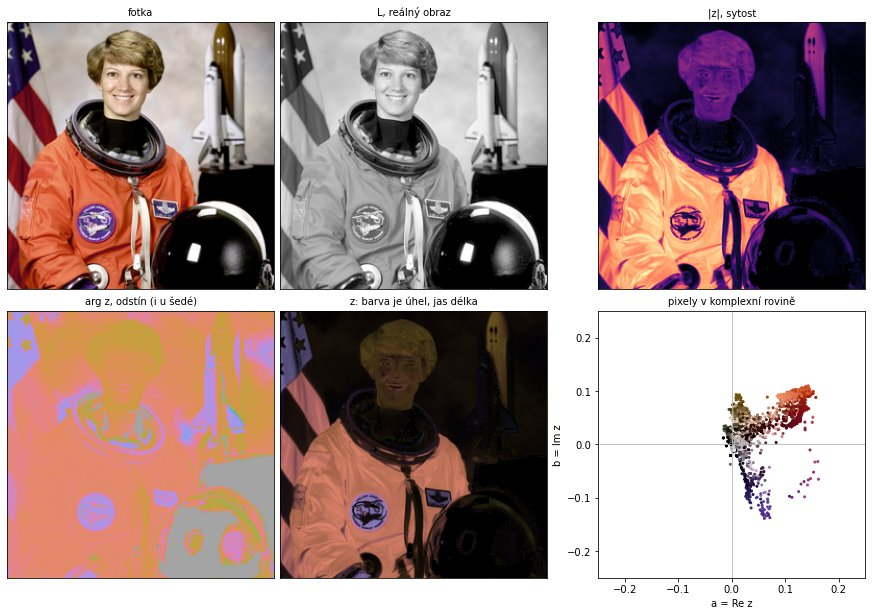

Nejsytější pixel má |z| = 0.186. Skoro šedých pixelů, s |z| pod 0.02, je 51%.

In [4]:
# Interactive picture: a picture as its lightness and its complex picture.
def look(name):
    rgb = PICTURES[name]
    L, z = to_oklab(rgb)
    fig = Figure(figsize=(12, 8.4), layout="constrained")
    axes = fig.subplots(2, 3).ravel()
    panel(axes[0], rgb, name)
    panel(axes[1], L, "L, reálný obraz", vmin=0, vmax=1)
    panel(axes[2], np.abs(z), "|z|, sytost", cmap="magma", vmin=0)
    panel(axes[3], hue_picture(z, brightness=False), "arg z, odstín (i u šedé)")
    panel(axes[4], hue_picture(z), "z: barva je úhel, jas délka")
    plane(axes[5], z, rgb, 0.25, "pixely v komplexní rovině")
    grey = np.mean(np.abs(z) < 0.02)
    return fig, (f"Nejsytější pixel má |z| = {np.abs(z).max():.3f}. "
                 f"Skoro šedých pixelů, s |z| pod 0.02, je {grey:.0%}.")


explore(look, name=("obrázek", list(PICTURES)))

Odstín $\arg z$ je u šedých ploch jen šum: šipka je tam skoro nulová a její úhel nic neznamená, stejně jako fáze slabé vlny ve spektru. Proto se komplexní obraz kreslí s jasem podle délky, a slabé šipky zmizí do černé. U barevného kruhu je úhel vidět nejlépe: odstín se točí kolem středu a sytost roste k okraji.

## 2. Počítání s barvou

Komplexní číslo $w$ s délkou 1 a úhlem $\theta$ je

$$w = \cos\theta + i \sin\theta = e^{i\theta}$$

Násobení $z \cdot w$ šipku otočí o $\theta$ a délku nechá. Všechny barvy obrázku se tedy posunou po barevném kruhu o stejný úhel a sytost i světlost zůstanou. Je to tatáž operace, jakou v lekci 4 dělá posun obrázku s fází každého koeficientu. Obecné komplexní číslo $s \cdot e^{i\theta}$ šipku otočí a její délku vynásobí $s$. Přičtení šipky $c$ posune všechny barvy stejně:

| Operace | Co udělá s barvou |
|---|---|
| $z \cdot e^{i\theta}$ | otočí odstín o $\theta$ |
| $z \cdot s$, $s$ reálné | změní sytost: $s = 0$ dá šedou fotku, $s > 1$ přesytí |
| $z + c$ | tónuje, celý mrak bodů se posune a šedá přestane být šedá |
| $\overline{z} = a - ib$ | zrcadlí odstíny přes osu $a$, modrá a žlutá se prohodí |

Obrázek níže počítá $s \cdot e^{i\theta} \cdot z + c$. Při $\theta = 180°$ je $w = -1$ a každá barva přejde na doplňkovou, oranžová na modrou. Světlost zůstane, takže to není negativ. Některé otočené nebo přesycené barvy se do sRGB nevejdou a oříznou se, kolik jich je, říká popisek.

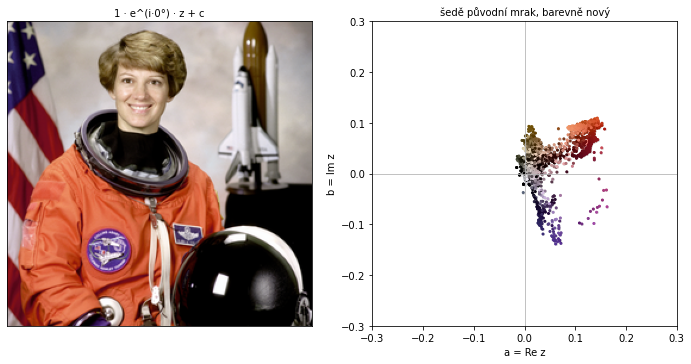

Do sRGB se nevejde a ořízne se 0% pixelů.

In [5]:
# Interactive picture: s e^(i theta) z + c, a turn, a stretch and a shift of every arrow.
def turn(name, theta, s, tint_angle, tint):
    rgb = PICTURES[name]
    L, z = to_oklab(rgb)
    c = tint * np.exp(1j * np.radians(tint_angle))
    turned = s * np.exp(1j * np.radians(theta)) * z + c
    result = from_oklab(L, turned)
    fig = Figure(figsize=(12, 5.6))
    axes = fig.subplots(1, 2)
    panel(axes[0], result, f"{s:g} · e^(i·{theta}°) · z + c")
    axes[1].scatter(z.ravel()[PICK].real, z.ravel()[PICK].imag, color="0.85", s=3)
    plane(axes[1], turned, result, 0.3, "šedě původní mrak, barevně nový")
    if tint:
        axes[1].annotate("", xy=(c.real, c.imag), xytext=(0, 0), zorder=5,
                         arrowprops={"arrowstyle": "-|>", "color": "C0", "lw": 3, "mutation_scale": 18})
    text = f"Do sRGB se nevejde a ořízne se {outside(L, turned):.0%} pixelů."
    return fig, text + (" Modrá šipka je c, o kterou se posunul celý mrak." if tint else "")


explore(turn, name=("obrázek", list(PICTURES)),
        theta=("θ", Steps(range(0, 361, 15))),
        s=("s", Steps([0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0], start=1.0)),
        tint_angle=("směr c", Steps(range(0, 360, 30), start=60)),
        tint=("délka c", Steps([0.0, 0.01, 0.02, 0.04, 0.06])))

### 🎯 Úkol 1: otočení odstínu v kernelu

Kernel `Hue` převede pixel do OKLabu a zpátky. V `lab.yz` je komplexní číslo pixelu jako `vec2`, reálná část v `x`, imaginární v `y`, stejně jako v kernelech lekce 4. Doplňte řádek s `TODO`: vynásobte `z` číslem $s \cdot e^{i\theta}$ a výsledek zapište zpátky do `lab.yz`. Dvě komplexní čísla se násobí podle

$$(a + bi)(c + di) = (ac - bd) + (ad + bc)\,i$$

Nedokončený kernel vrátí fotku beze změny.

<details><summary>💡 Nápověda</summary>

1. Šipku $s \cdot e^{i\theta}$ si uložte do `vec2 w`: `s * vec2(cos(...), sin(...))`. Posuvník `theta` je ve stupních, `radians` ho převede.
2. Součin napište po složkách jako `vec2(reálná část, imaginární část)`, s `z.x`, `z.y`, `w.x` a `w.y`. Swizzle funguje i pro zápis, `lab.yz = ...`.
</details>

<details><summary>🔑 Řešení</summary>

```python
    vec2 w = s * vec2(cos(radians(theta)), sin(radians(theta)))
    lab.yz = vec2(z.x * w.x - z.y * w.y, z.x * w.y + z.y * w.x)
```
</details>

GPU 0.60 ms, round trip 77 ms

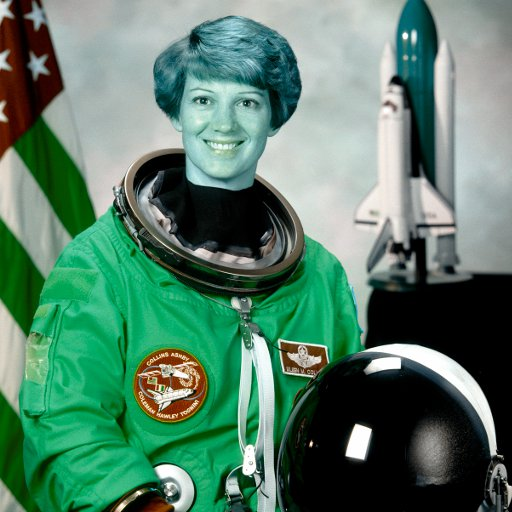

In [6]:
%%gmacs "astronaut" -> "Hue"
import linear_srgb_color_space
import oklab_color_space

uniform float theta: hint_range(0, 360) = 120.0
uniform float s: hint_range(0, 2) = 1.0


def pixel(ivec2 at) -> vec4:
    vec3 lab = linear_srgb_to_oklab(srgb_to_linear_srgb(src(at).rgb))
    vec2 z = lab.yz                  # the pixel's complex number, a in x and b in y
    # TODO: z times s e^(i theta), by the rule for multiplying two complex numbers
    vec3 rgb = clamp(oklab_to_linear_srgb(lab), vec3(0.0), vec3(1.0))
    return vec4(linear_srgb_to_srgb(rgb), 1.0)

### ✅ Kontrola

Buňka otočí odstíny fotky stejně v NumPy a porovná výsledek s vrstvou `Hue`. Počítá s posuvníky kernelu ve výchozím stavu, $\theta = 120°$ a $s = 1$. Pokud jste jimi hýbali, nastavte `theta` a `s` v buňce na jejich hodnoty.

In [7]:
theta, s = 120.0, 1.0                       # the kernel's sliders
L, z = to_oklab(photo.read()[..., :3])
sara.check("Hue", rgba(from_oklab(L, s * np.exp(1j * np.radians(theta)) * z)))

largest difference 0.0000081 at x 121, y 465, 0 % of pixels differ by more than 0.01


Difference(largest=8.052214980125427e-06, where=(121, 465), percent=0.0)

### 🎯 Úkol 2: vyvážení bílé

Fotka pod žárovkou má všechny barvy posunuté k oranžové, ke každé šipce se přičetla stejná šipka $c$. Vyvážení bílé ji odečte. Jak velká je, se dá odhadnout předpokladem *šedého světa* (*gray world*): průměrná barva scény je šedá, takže průměrná šipka obrázku má být nula. Co z nuly vybočuje, je barva světla.

Doplňte `white_balance`, aby od každého pixelu odečetla průměrnou šipku obrázku. Buňka pod ní fotku oteplí a vyváží zpátky.

<details><summary>💡 Nápověda</summary>

`z.mean()` je průměr všech komplexních čísel pole, zase komplexní číslo. NumPy ho od pole odečte po prvcích.
</details>

<details><summary>🔑 Řešení</summary>

```python
def white_balance(z):
    """z moved by one arrow, so that the mean colour of the picture is grey, z = 0."""
    return z - z.mean()
```
</details>

In [8]:
def white_balance(z):
    """z moved by one arrow, so that the mean colour of the picture is grey, z = 0."""
    # TODO: subtract the picture's mean arrow from every pixel
    return z

length of the mean arrow, the photo:      0.0473
length of the mean arrow, the warm photo: 0.0834
length of the mean arrow, balanced:       0.0000


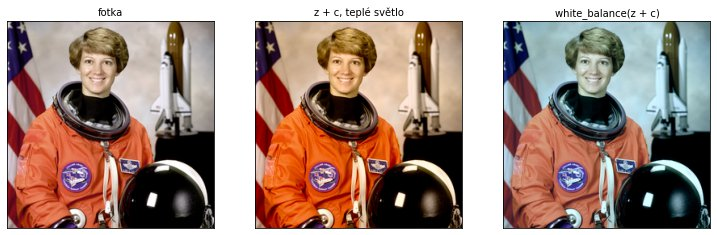

In [9]:
L, z = to_oklab(PICTURES["fotka"])
warm = 0.04 * np.exp(1j * np.radians(70))      # a small arrow towards orange, a tungsten bulb's cast
balanced = white_balance(z + warm)
print(f"length of the mean arrow, the photo:      {abs(z.mean()):.4f}")
print(f"length of the mean arrow, the warm photo: {abs((z + warm).mean()):.4f}")
print(f"length of the mean arrow, balanced:       {abs(balanced.mean()):.4f}")
show_pictures([(from_oklab(L, z), "fotka"), (from_oklab(L, z + warm), "z + c, teplé světlo"),
               (from_oklab(L, balanced), "white_balance(z + c)")])

Vyvážená fotka je o něco studenější než původní. Fotka astronauta šedý svět nesplňuje: oranžový skafandr a vlajka posunou průměr k teplým barvám, a vyvážení ten posun vezme i fotce samotné. Proto fotoaparáty průměrují jen pixely, které už skoro šedé jsou, nebo hledají nejsvětlejší plochu a berou ji jako bílou.

## 3. Spektrum komplexního obrazu

V lekci 4 má reálný obraz spektrum souměrné: $F(-u, -v) = \overline{F(u, v)}$, a kosinusovka proto dá dva body. Důvod je Eulerův vzorec,

$$\cos\varphi = \frac{e^{i\varphi} + e^{-i\varphi}}{2}$$

Kosinus je součet dvou šipek, které se točí opačně, a transformace najde každou zvlášť. Komplexní obraz takové omezení nemá. Duha, ve které se odstín podél osy $x$ točí dokola,

$$z = 0.1\, e^{2\pi i\, u x / N}$$

je přesně jedna z vln Fourierovy transformace, a její spektrum je proto **jeden** bod. Duha točená opačně, $\overline{z}$, má bod na druhé straně. Samotná složka $a = \operatorname{Re} z$ je obyčejný kosinus a má body dva.

Obě duhy vypadají skoro stejně, liší se jen pořadím barev: zleva doprava jde jednou od červené přes žlutou k zelené a modré, podruhé obráceně. Reálný obraz tenhle rozdíl nést nemůže, komplexní ano. Pravý obrázek ukazuje, jak moc se liší $|F|$ v bodech $(u, v)$ a $(-u, -v)$. U světlosti fotky je všude nula, u barvy $z$ ne: rozdíl říká, kterým směrem se odstíny fotky v dané frekvenci točí.

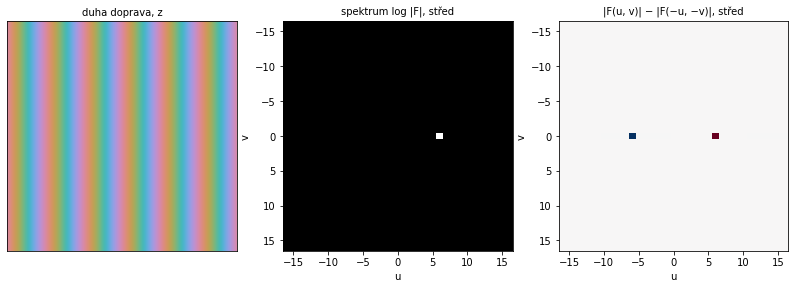

Největší odchylka od souměrnosti, |F(u, v) − conj F(−u, −v)| / max |F|: 1.0e+00. Body (u, v): (6, 0).

In [10]:
# Interactive picture: the spectrum of a complex picture is not symmetric.
SIGNALS = ["duha doprava, z", "duha doleva, conj z", "jen a = Re z, kosinus",
           "fotka, světlost L", "fotka, barva z"]


def signed_log(a):
    s = np.sign(a) * np.log1p(np.abs(a))
    return s / max(np.abs(s).max(), 1e-9)


def spin(signal, u):
    n = 256
    x = np.indices((n, n))[1]
    rainbow = 0.1 * np.exp(2j * np.pi * u * x / n)
    L, z = to_oklab(PICTURES["fotka"])
    f = {"duha doprava, z": rainbow, "duha doleva, conj z": np.conj(rainbow),
         "jen a = Re z, kosinus": rainbow.real + 0j, "fotka, světlost L": L + 0j, "fotka, barva z": z}[signal]
    F = np.fft.fftshift(np.fft.fft2(f))
    twin = np.conj(np.roll(F[::-1, ::-1], 1, axis=(0, 1)))      # conj F(-u, -v), with the middle kept in place
    magnitude = np.log1p(np.abs(F))
    gap = signed_log(np.abs(F) - np.abs(twin))
    zoom = not signal.startswith("fotka")
    middle = slice(n // 2 - 16, n // 2 + 17) if zoom else slice(None)
    extent = (-16.5, 16.5, 16.5, -16.5) if zoom else (-128.5, 127.5, 127.5, -128.5)
    if signal == "fotka, světlost L":
        picture = np.dstack([L] * 3)
    elif signal == "fotka, barva z":
        picture = hue_picture(z)
    else:
        picture = from_oklab(np.full((n, n), 0.72), f)
    fig = Figure(figsize=(14, 4.8))
    axes = fig.subplots(1, 3)
    panel(axes[0], np.clip(picture, 0, 1), signal)
    for ax, a, title, keys in ((axes[1], magnitude[middle, middle] / magnitude.max(), "spektrum log |F|", {"vmin": 0, "vmax": 1}),
                               (axes[2], gap[middle, middle], "|F(u, v)| − |F(−u, −v)|", {"cmap": "RdBu_r", "vmin": -1, "vmax": 1})):
        ax.imshow(a, extent=extent, interpolation="nearest", cmap=keys.pop("cmap", "gray"), **keys)
        ax.set_title(title + (", střed" if zoom else ""), fontsize=10)
        ax.set_xlabel("u")
        ax.set_ylabel("v")
    asymmetry = np.abs(F - twin).max() / np.abs(F).max()
    text = f"Největší odchylka od souměrnosti, |F(u, v) − conj F(−u, −v)| / max |F|: {asymmetry:.1e}."
    if zoom:
        dots = np.argwhere(np.abs(F) > 0.01 * np.abs(F).max()) - n // 2
        text += " Body (u, v): " + ", ".join(f"({du}, {dv})" for dv, du in dots) + "."
    return fig, text


explore(spin, signal=("obraz", SIGNALS), u=("frekvence duhy", (6, 1, 12)))

### Dvě transformace za cenu jedné

Souměrnost má i praktický důsledek. Spektrum reálného obrazu má polovinu čísel navíc, druhá polovina je jen zrcadlo. Komplexní obraz zaplní celé. Proto se dva reálné obrazy dají transformovat jednou transformací: složí se do $z = a + ib$, transformuje se $z$ a spektra $a$ a $b$ se oddělí podle souměrnosti,

$$A(u, v) = \frac{Z(u, v) + \overline{Z(-u, -v)}}{2}, \qquad B(u, v) = \frac{Z(u, v) - \overline{Z(-u, -v)}}{2i}$$

Buňka níže to udělá pro složky $a$ a $b$ fotky a porovná je s dvěma samostatnými transformacemi. Rozdíl je na úrovni zaokrouhlení. Stejně šetří knihovny FFT práci u reálných vstupů.

In [11]:
L, z = to_oklab(PICTURES["fotka"])
Fz = np.fft.fft2(z)                                       # one transform of the complex picture
mirror = np.conj(np.roll(Fz[::-1, ::-1], 1, axis=(0, 1)))  # conj F(-u, -v), the index N - k is frequency -k
Fa = (Fz + mirror) / 2                                    # the spectrum of a = Re z
Fb = (Fz - mirror) / 2j                                   # the spectrum of b = Im z
print("a: largest difference from np.fft.fft2(z.real):", f"{np.abs(Fa - np.fft.fft2(z.real)).max():.1e}")
print("b: largest difference from np.fft.fft2(z.imag):", f"{np.abs(Fb - np.fft.fft2(z.imag)).max():.1e}")

a: largest difference from np.fft.fft2(z.real): 2.3e-13
b: largest difference from np.fft.fft2(z.imag): 1.1e-13


## 4. Gradient jako komplexní obraz

Šipka v pixelu nemusí být barva. Gradient světlosti, rozdíl sousedních pixelů ve směru $x$ a $y$ z lekce o konvoluci, je zase dvojice čísel v pixelu:

$$g = \partial_x L + i\,\partial_y L$$

Šipka $g$ míří kolmo na hranu, od tmavé strany ke světlé. Její délka je síla hrany a její úhel směr. Násobení $i$ ji otočí o 90°, takže $i \cdot g$ míří **podél** hrany. Tím směrem by tahy štětce sledovaly tvar.

Gradient je ale neklidný, a směr hran se proto průměruje přes okolí. Tady narazí obyčejný průměr: hrana z tmavé do světlé a hrana ze světlé do tmavé mají stejný směr, ale opačné šipky $g$ a $-g$, a v průměru se vyruší. Pomůže druhá mocnina. Umocnění šipku zdvojí v úhlu, a $g^2$ a $(-g)^2$ jsou totéž číslo. Průměrují se tedy $g^2$ a odmocnina úhel zase vydělí dvěma. V obrázku níže je to nejlépe vidět na tenkých kroužcích, kde se gradient obrací každou půlperiodu.

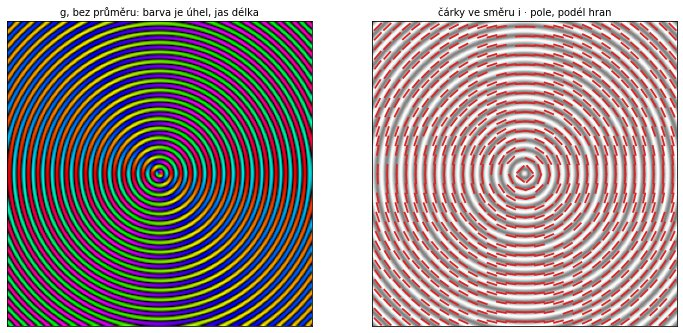

Bez průměru je každý pixel sám za sebe.

In [12]:
# Interactive picture: the directions of edges, from the gradient as a complex picture.
FIELDS = ["g, bez průměru", "průměr g", "průměr g², pak odmocnina"]


def flow(name, field, sigma):
    L = {"kroužky": rings(), "cihly": BRICK}.get(name)
    L = to_oklab(PICTURES[name])[0] if L is None else L
    gy, gx = np.gradient(L)
    g = gx + 1j * gy
    if field == "g, bez průměru":
        shown, along = g, 1j * g
    elif field == "průměr g":
        shown = blur(g, sigma)
        along = 1j * shown
    else:
        shown = blur(g ** 2, sigma)                   # twice the angle, so g and -g agree
        along = 1j * np.sqrt(shown)                   # back to the angle of the edge, up to the sign
    squared = field.startswith("průměr g²")
    top = np.percentile(np.abs(g) ** (2 if squared else 1), 99)     # the scale before the mean, so what cancels goes dark
    fig = Figure(figsize=(12, 6))
    axes = fig.subplots(1, 2)
    panel(axes[0], arrows_picture(shown, top), field + ": barva je úhel, jas délka")
    panel(axes[1], L, "čárky ve směru i · pole, podél hran", alpha=0.5)
    ys, xs = np.mgrid[4:256:8, 4:256:8]
    t = along[ys, xs]
    keep = np.abs(t) > 0.1 * np.abs(g).max()
    t = t[keep] / np.abs(t[keep])
    axes[1].quiver(xs[keep], ys[keep], t.real, t.imag, color="C3", angles="xy", scale=28, width=0.006,
                   headwidth=0, headlength=0, headaxislength=0, pivot="mid")
    if field == "g, bez průměru":
        return fig, "Bez průměru je každý pixel sám za sebe."
    kept = np.mean(np.abs(shown)) / np.mean(np.abs(g) ** (2 if squared else 1))
    return fig, f"Po průměru zbylo {kept:.0%} průměrné délky šipek, zbytek se vyrušil."


explore(flow, name=("obrázek", ["kroužky", "fotka", "cihly"]), field=("pole", FIELDS),
        sigma=("σ průměru", (4, 1, 12)))

Průměr $g^2$ je zkrácená podoba **strukturního tenzoru** (*structure tensor*): jeho dvě čísla, $g_x^2 - g_y^2$ a $2 g_x g_y$, jsou reálná a imaginární část $g^2$. Z takového pole směrů vychází malba podél hran, anizotropní Kuwahara a čáry podél hran (*edge tangent flow*), o kterých mluví lekce 5. Rozmazání v obrázku jde přes spektrum jako v sekci 5 lekce 4, a funguje i pro komplexní pole.

## Shrnutí

- Dvojice čísel v pixelu je komplexní číslo. U barvy v OKLabu je délka sytost a úhel odstín, stejně jako u koeficientu spektra amplituda a fáze.
- Násobení $e^{i\theta}$ otočí odstíny, násobení reálným $s$ mění sytost, přičtení $c$ tónuje a odečtení průměru vyváží bílou.
- Kernel násobí komplexní čísla jako `vec2` podle $(ac - bd) + (ad + bc)\,i$, stejně jako druhý průchod DFT v lekci 4.
- Spektrum reálného obrazu je souměrné, protože kosinus jsou dvě opačně točené šipky. Spektrum komplexního obrazu souměrné být nemusí a nese o polovinu víc informace. Dva reálné obrazy proto stačí transformovat jednou.
- Gradient je komplexní obraz šipek kolmých na hrany. Směry hran se průměrují přes $g^2$, ve kterém se šipky $g$ a $-g$ nevyruší.

### Bonusové úkoly

1. **Komplexně sdružené barvy.** Napište kernel, který místo otočení prohodí znaménko $b$, $\overline{z}$. Které barvy se změní nejvíc a které vůbec?
2. **Šedý svět jen ze šedých pixelů.** Upravte `white_balance`, aby průměrovala jen pixely s $\lvert z \rvert$ pod nějakou mezí, a porovnejte s fotkou astronauta výše.
3. **Dvě DFT v jednom kernelu.** První průchod kernelu `DFT rows` v lekci 4 transformuje jen světlost. Složte do něj $a$ a $b$ fotky jako jedno komplexní číslo a oddělte jejich spektra podle souměrnosti ze sekce 3.